In [61]:
import numpy as np
import matplotlib.pyplot as plt
from zipfile import ZipFile
from tensorflow import keras
from tensorflow.keras import layers

In [62]:
with ZipFile("C:\\Users\\ADMIN\\Downloads\\brain tumour.zip") as z:
    z.extractall("brain_data")

train_path = ("brain_data/Training")
test_path = ("brain_data/Testing")

print("Data Extracted successfully")

Data Extracted successfully


In [63]:
train_ds = keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset='training',
    seed=42,
    image_size = (64,64),
    batch_size = 32
)
val_ds = keras.utils.image_dataset_from_directory(
    train_path,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=(64, 64),
    batch_size=32
)
test_ds = keras.utils.image_dataset_from_directory(
    test_path,
    image_size=(64,64),
    batch_size=32,
    shuffle=False

)

Found 2870 files belonging to 4 classes.
Using 2296 files for training.
Found 2870 files belonging to 4 classes.
Using 574 files for validation.
Found 394 files belonging to 4 classes.


In [64]:
class_names = train_ds.class_names
print("Classes:",class_names)

Classes: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']


In [65]:
model = keras.Sequential ([
    keras.Input(shape=(64,64,3)),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),

    layers.Rescaling(1.0/255),
    layers.Conv2D(32,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,(3,3),activation="relu"),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64,activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(4,activation="softmax"),
    
])
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation_5               │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_4 (RandomZoom)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │       802,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 822,532 (3.14 MB)

 Trainable params: 822,532 (3.14 MB)

 Non-trainable params: 0 (0.00 B)

In [66]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [67]:
early_stop = keras.callbacks.EarlyStopping (
    monitor="val_loss",
    patience = 3,
    restore_best_weights=True
)

In [68]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop]
)

Epoch 1/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 11s 90ms/step - accuracy: 0.4760 - loss: 1.1935 - val_accuracy: 0.6167 - val_loss: 0.9161
Epoch 2/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 6s 87ms/step - accuracy: 0.6024 - loss: 0.9618 - val_accuracy: 0.6742 - val_loss: 0.8116
Epoch 3/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 98ms/step - accuracy: 0.6533 - loss: 0.8386 - val_accuracy: 0.6899 - val_loss: 0.7739
Epoch 4/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 6s 83ms/step - accuracy: 0.6738 - loss: 0.7777 - val_accuracy: 0.6707 - val_loss: 0.7048
Epoch 5/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 6s 81ms/step - accuracy: 0.7217 - loss: 0.6979 - val_accuracy: 0.7509 - val_loss: 0.5735
Epoch 6/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 6s 82ms/step - accuracy: 0.7352 - loss: 0.6530 - val_accuracy: 0.7857 - val_loss: 0.5113
Epoch 7/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 6s 78ms/step - accuracy: 0.7456 - loss: 0.6318 - val_accuracy: 0.7561 - val_loss: 0.5843
Epoch 8/15
72/72 ━━━━━━━━━━━━━━━━━━━━ 6s 77ms/step - accuracy: 0.7470 - loss: 0.6050 - val_accuracy: 0.7561 - 

In [69]:
loss,accuracy = model.evaluate(test_ds)
print("Test Accuracy", round(accuracy * 100 , 2),"%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.4442 - loss: 2.2084
Test Accuracy 44.42 %


In [70]:
images,labels = next(iter(test_ds))

In [71]:
prediction = model.predict(images[:1],verbose=0)

In [72]:
predicted = np.argmax(prediction[0])

In [73]:
print("Predicted :",class_names[predicted])
print("Actual :",class_names[int(labels[0])])
      

Predicted : no_tumor
Actual : glioma_tumor


In [79]:
plt.imshow(images[0].numpy().astype("uint8"))

plt.title("Predicted: " + class_names[predicted])
plt.axis("off")
plt.show()

TypeError: 'numpy.ndarray' object is not callable

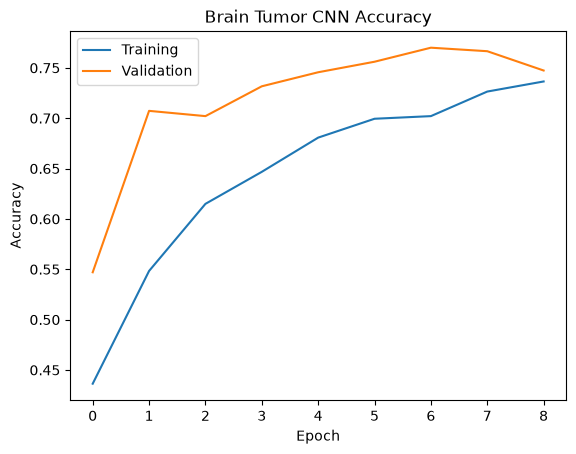

In [ ]:
plt.plot(history.history["accuracy"], label="Training")

plt.plot(history.history["val_accuracy"], label="Validation")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.title("Brain Tumor CNN Accuracy")

plt.legend()

plt.show()

In [ ]:
print("Training Accuracy:", round(train_acc * 100, 2), "%")

print("Validation Accuracy:", round(val_acc * 100, 2), "%")
print("Accuracy Difference:", round((train_acc - val_acc) * 100, 2), "percentage points")